# Cell 1 — imports + 한글 폰트 설정

In [1]:
# Cell 1: imports + 한글 폰트 설정
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.font_manager as fm

# 한글 폰트 설정 (Windows)
candidates = ["Malgun Gothic", "맑은 고딕", "NanumGothic", "Gulim"]
available = {f.name for f in fm.fontManager.ttflist}
chosen = next((c for c in candidates if c in available), None)
if chosen:
    matplotlib.rcParams["font.family"] = chosen
    matplotlib.rcParams["axes.unicode_minus"] = False
    print(f"한글 폰트 설정 완료: {chosen}")
else:
    print("한글 폰트 못 찾음")

print(f"pandas {pd.__version__} / numpy {np.__version__}")

한글 폰트 설정 완료: Malgun Gothic
pandas 2.2.3 / numpy 1.26.4


# Cell 2 — 경로 설정 + 존재 검증

In [2]:
# Cell 2: 경로 설정 + 존재 검증
DATA_ROOT = Path(r"D:\pill_detection\data")

# Kaggle
KAGGLE_TRAIN_IMAGES = DATA_ROOT / "train_images"
KAGGLE_TRAIN_ANNOTATIONS = DATA_ROOT / "train_annotations"
KAGGLE_TEST_IMAGES = DATA_ROOT / "test_images"

# TS/TL 시리즈 (1, 3, 4, 5, 6, 7, 8)
SERIES_NUMBERS = [1, 3, 4, 5, 6, 7, 8]
TS_DIRS = {n: DATA_ROOT / f"TS_{n}_조합" for n in SERIES_NUMBERS}
TL_DIRS = {n: DATA_ROOT / f"TL_{n}_조합" for n in SERIES_NUMBERS}

# 존재 검증
print("=" * 60)
print("경로 존재 검증")
print("=" * 60)

paths_to_check = {
    "KAGGLE_TRAIN_IMAGES": KAGGLE_TRAIN_IMAGES,
    "KAGGLE_TRAIN_ANNOTATIONS": KAGGLE_TRAIN_ANNOTATIONS,
    "KAGGLE_TEST_IMAGES": KAGGLE_TEST_IMAGES,
}
for n in SERIES_NUMBERS:
    paths_to_check[f"TS_{n}"] = TS_DIRS[n]
    paths_to_check[f"TL_{n}"] = TL_DIRS[n]

missing = []
for name, path in paths_to_check.items():
    exists = path.exists()
    mark = "✅" if exists else "❌"
    print(f"{mark} {name:30s} {path}")
    if not exists:
        missing.append(name)

print("=" * 60)
if missing:
    print(f"🔴 누락된 경로 {len(missing)}개: {missing}")
else:
    print(f"✅ 전체 {len(paths_to_check)}개 경로 모두 존재")

경로 존재 검증
✅ KAGGLE_TRAIN_IMAGES            D:\pill_detection\data\train_images
✅ KAGGLE_TRAIN_ANNOTATIONS       D:\pill_detection\data\train_annotations
✅ KAGGLE_TEST_IMAGES             D:\pill_detection\data\test_images
✅ TS_1                           D:\pill_detection\data\TS_1_조합
✅ TL_1                           D:\pill_detection\data\TL_1_조합
✅ TS_3                           D:\pill_detection\data\TS_3_조합
✅ TL_3                           D:\pill_detection\data\TL_3_조합
✅ TS_4                           D:\pill_detection\data\TS_4_조합
✅ TL_4                           D:\pill_detection\data\TL_4_조합
✅ TS_5                           D:\pill_detection\data\TS_5_조합
✅ TL_5                           D:\pill_detection\data\TL_5_조합
✅ TS_6                           D:\pill_detection\data\TS_6_조합
✅ TL_6                           D:\pill_detection\data\TL_6_조합
✅ TS_7                           D:\pill_detection\data\TS_7_조합
✅ TL_7                           D:\pill_detection\data\TL_7_조합
✅ TS_8      

# Cell 3 — 핵심 헬퍼 함수

In [3]:
# Cell 3: 핵심 헬퍼 함수 3종
HIDDEN_PREFIXES = ("._",)
HIDDEN_NAMES = {".DS_Store", "Thumbs.db", "desktop.ini"}


def is_hidden_meta(path: Path) -> bool:
    """macOS AppleDouble / Windows 썸네일 등 숨김 메타 파일 판별."""
    return path.name.startswith(HIDDEN_PREFIXES) or path.name in HIDDEN_NAMES


def parse_bbox(bbox):
    """
    bbox 원본 → (valid, x, y, w, h).
    - 리스트 아니거나 길이 != 4 → invalid
    - float 변환 실패 → invalid
    - 음수/0 크기는 일단 valid 처리 (이슈 플래그는 02_eda에서)
    """
    if not isinstance(bbox, list) or len(bbox) != 4:
        return False, None, None, None, None
    try:
        vals = [float(v) for v in bbox]
        return True, vals[0], vals[1], vals[2], vals[3]
    except (TypeError, ValueError):
        return False, None, None, None, None


ANGLE_PATTERN = re.compile(r"_(\d{2,3})_(\d{3})_(\d{3})\.?\w*$")


def extract_angle_from_filename(filename: str):
    """파일명에서 각도(70/75/90 등) 추출. 매칭 실패 시 None."""
    m = ANGLE_PATTERN.search(filename)
    return int(m.group(1)) if m else None


# --- self-test ---
print("=== is_hidden_meta ===")
for name in ["._.DS_Store", ".DS_Store", "K-004378_70_000_200.json", "Thumbs.db"]:
    print(f"  {name:40s} -> {is_hidden_meta(Path(name))}")

print("\n=== parse_bbox ===")
test_bboxes = [
    [100, 200, 50, 80],          # 정상
    [],                           # 빈 배열
    [111, 203291, 393],          # 쉼표 누락 (길이 3)
    [592, 54, "251.465"],        # 길이 3 + 문자열
    None,                         # None
    [1, 2, 3, "abc"],            # 변환 실패
]
for b in test_bboxes:
    print(f"  {str(b):40s} -> {parse_bbox(b)}")

print("\n=== extract_angle_from_filename ===")
test_names = [
    "K-004378-005002_70_000_200.png",
    "K-004378-005002_90_000_200.json",
    "K-004378-005002_index.png",
    "random_file.png",
]
for n in test_names:
    print(f"  {n:45s} -> {extract_angle_from_filename(n)}")

=== is_hidden_meta ===
  ._.DS_Store                              -> True
  .DS_Store                                -> True
  K-004378_70_000_200.json                 -> False
  Thumbs.db                                -> True

=== parse_bbox ===
  [100, 200, 50, 80]                       -> (True, 100.0, 200.0, 50.0, 80.0)
  []                                       -> (False, None, None, None, None)
  [111, 203291, 393]                       -> (False, None, None, None, None)
  [592, 54, '251.465']                     -> (False, None, None, None, None)
  None                                     -> (False, None, None, None, None)
  [1, 2, 3, 'abc']                         -> (False, None, None, None, None)

=== extract_angle_from_filename ===
  K-004378-005002_70_000_200.png                -> 70
  K-004378-005002_90_000_200.json               -> 90
  K-004378-005002_index.png                     -> None
  random_file.png                               -> None


# Cell 4 — Kaggle 로더

In [7]:
# Cell 4 (재작성): Kaggle train 로더 - 재귀 + 메타 필드 전량 보존
# 보존 대상 images 필드 (48개 중 의미있는 것)
IMAGE_META_FIELDS = [
    "file_name", "width", "height", "imgfile",
    "drug_N", "drug_S", "back_color", "drug_dir", "light_color",
    "camera_la", "camera_lo", "size",
    "dl_idx", "dl_mapping_code", "dl_name", "dl_name_en",
    "img_key", "dl_material", "dl_material_en", "dl_custom_shape",
    "dl_company", "dl_company_en", "di_company_mf", "di_company_mf_en",
    "item_seq", "di_item_permit_date", "di_class_no", "di_etc_otc_code",
    "di_edi_code", "chart",
    "drug_shape", "thick", "leng_long", "leng_short",
    "print_front", "print_back", "color_class1", "color_class2",
    "line_front", "line_back",
    "img_regist_ts", "form_code_name",
    "mark_code_front_anal", "mark_code_back_anal",
    "mark_code_front_img", "mark_code_back_img",
    "mark_code_front", "mark_code_back",
    "change_date", "id",
]


def load_kaggle_train(images_dir: Path, annotations_dir: Path) -> pd.DataFrame:
    """
    Kaggle train 데이터 로드 → 통합 스키마 DataFrame.
    
    구조 (실측):
    annotations_dir/
    └── {조합}_json/
        └── {K-code}/
            └── {파일명}_{각도}_000_200.json
    
    각 JSON: images(len 1) + annotations(len 1) + categories(len 1)
    """
    records = []
    
    # 재귀적으로 모든 .json 수집 (메타 파일 제외)
    all_json_paths = sorted([
        p for p in annotations_dir.rglob("*.json")
        if not is_hidden_meta(p)
    ])
    
    for jp in all_json_paths:
        # 조합명 추출: .../{조합}_json/{K-code}/{filename}.json
        try:
            combo_folder = jp.parent.parent.name  # "..._json"
            combo = combo_folder.removesuffix("_json") if combo_folder.endswith("_json") else combo_folder
            kcode_folder = jp.parent.name
        except Exception:
            combo = None
            kcode_folder = None
        
        try:
            with open(jp, "r", encoding="utf-8") as f:
                data = json.load(f)
        except Exception as e:
            records.append({
                "source": "kaggle_train",
                "source_json": str(jp.relative_to(annotations_dir)),
                "combo": combo,
                "kcode_folder": kcode_folder,
                "parse_error": f"json_load_fail: {e}",
            })
            continue
        
        images = data.get("images", [])
        annotations = data.get("annotations", [])
        categories = data.get("categories", [])
        
        # images[0] 메타 (없으면 빈 dict)
        img = images[0] if images else {}
        img_file = img.get("file_name")
        img_path_obj = images_dir / img_file if img_file else None
        angle = extract_angle_from_filename(img_file) if img_file else None
        
        # categories[0] (K-code -> name 매핑)
        cat = categories[0] if categories else {}
        
        # annotations 루프 (보통 1개이지만 안전하게)
        if not annotations:
            rec = {
                "source": "kaggle_train",
                "source_json": str(jp.relative_to(annotations_dir)),
                "combo": combo,
                "kcode_folder": kcode_folder,
                "image_file": img_file,
                "image_path": str(img_path_obj) if img_path_obj else None,
                "image_exists": img_path_obj.exists() if img_path_obj else False,
                "angle": angle,
                "parse_error": "no_annotations",
            }
            # 이미지 메타 전량
            for f in IMAGE_META_FIELDS:
                rec[f"img_{f}"] = img.get(f)
            records.append(rec)
            continue
        
        for ann in annotations:
            bbox_raw = ann.get("bbox")
            valid, bx, by, bw, bh = parse_bbox(bbox_raw)
            
            rec = {
                "source": "kaggle_train",
                "source_json": str(jp.relative_to(annotations_dir)),
                "combo": combo,
                "kcode_folder": kcode_folder,
                "image_file": img_file,
                "image_path": str(img_path_obj) if img_path_obj else None,
                "image_exists": img_path_obj.exists() if img_path_obj else False,
                "angle": angle,
                # 어노테이션
                "ann_id": ann.get("id"),
                "ann_image_id": ann.get("image_id"),
                "category_id_raw": ann.get("category_id"),
                "bbox_raw": bbox_raw,
                "bbox_valid": valid,
                "bbox_x": bx,
                "bbox_y": by,
                "bbox_w": bw,
                "bbox_h": bh,
                "area_raw": ann.get("area"),
                "iscrowd": ann.get("iscrowd"),
                "ignore": ann.get("ignore"),
                "segmentation": ann.get("segmentation"),
                # 카테고리
                "cat_id": cat.get("id"),
                "cat_name": cat.get("name"),
                "cat_supercategory": cat.get("supercategory"),
                "parse_error": None,
            }
            # 이미지 메타 전량
            for f in IMAGE_META_FIELDS:
                rec[f"img_{f}"] = img.get(f)
            records.append(rec)
    
    return pd.DataFrame(records)


# 실행 + 검증
df_kaggle = load_kaggle_train(KAGGLE_TRAIN_IMAGES, KAGGLE_TRAIN_ANNOTATIONS)

print(f"레코드 수:           {len(df_kaggle):>6}")
print(f"고유 이미지 파일:    {df_kaggle['image_file'].nunique():>6}")
print(f"고유 K-code (drug_N):{df_kaggle['img_drug_N'].nunique():>6}")
print(f"고유 조합:           {df_kaggle['combo'].nunique():>6}")
print(f"parse_error 레코드:  {df_kaggle['parse_error'].notna().sum():>6}")
print(f"bbox_valid=False:    {(df_kaggle['bbox_valid'] == False).sum():>6}")
print(f"image_exists=False:  {(df_kaggle['image_exists'] == False).sum():>6}")

print("\n각도 분포:")
print(df_kaggle['angle'].value_counts(dropna=False))

print(f"\n컬럼 수: {len(df_kaggle.columns)}")
print(f"\n상위 2행:")
df_kaggle.head(2)

레코드 수:              763
고유 이미지 파일:       232
고유 K-code (drug_N):    56
고유 조합:              114
parse_error 레코드:       0
bbox_valid=False:         0
image_exists=False:       0

각도 분포:
angle
90    277
75    249
70    237
Name: count, dtype: int64

컬럼 수: 75

상위 2행:


,source,source_json,combo,kcode_folder,image_file,image_path,image_exists,angle,ann_id,ann_image_id,...,img_img_regist_ts,img_form_code_name,img_mark_code_front_anal,img_mark_code_back_anal,img_mark_code_front_img,img_mark_code_back_img,img_mark_code_front,img_mark_code_back,img_change_date,img_id
0,kaggle_train,K-001900-016548-019607-029451_json\K-001900\K-...,K-001900-016548-019607-029451,K-001900,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,D:\pill_detection\data\train_images\K-001900-0...,True,70,133,34,...,20070910,나정,,,,,,,20160825,34
1,kaggle_train,K-001900-016548-019607-029451_json\K-001900\K-...,K-001900-016548-019607-029451,K-001900,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,D:\pill_detection\data\train_images\K-001900-0...,True,75,134,35,...,20070910,나정,,,,,,,20160825,35


# Cell 5 — 7개 TL 시리즈 구조 진단

In [8]:
# Cell 5: TL 시리즈 1,3,4,5,6,7,8 구조 진단
# 각 시리즈에서 JSON 1개씩 까서 구조·필드 비교

def diagnose_tl_series(series_num: int, tl_dir: Path) -> dict:
    """TL 시리즈 한 개의 구조 진단."""
    result = {"series": series_num, "tl_dir": str(tl_dir)}
    
    # 직속 자식 (조합 폴더)
    children = [p for p in tl_dir.iterdir() if not is_hidden_meta(p)]
    combo_dirs = [p for p in children if p.is_dir()]
    result["combo_count"] = len(combo_dirs)
    result["sample_combo"] = combo_dirs[0].name if combo_dirs else None
    
    if not combo_dirs:
        result["error"] = "조합 폴더 없음"
        return result
    
    # 첫 조합 폴더의 하위 구조
    first_combo = combo_dirs[0]
    sub = [p for p in first_combo.iterdir() if not is_hidden_meta(p)]
    sub_dirs = [p for p in sub if p.is_dir()]
    sub_files = [p for p in sub if p.is_file()]
    result["first_combo_subdirs"] = len(sub_dirs)
    result["first_combo_subfiles"] = len(sub_files)
    result["first_combo_subdir_names"] = [p.name for p in sub_dirs[:5]]
    
    # 첫 K-code 폴더의 JSON 파일들
    if sub_dirs:
        first_kcode = sub_dirs[0]
        jsons = sorted([p for p in first_kcode.iterdir() 
                        if p.suffix == ".json" and not is_hidden_meta(p)])
        result["first_kcode_json_count"] = len(jsons)
        result["first_kcode_json_names"] = [p.name for p in jsons]
        
        # 첫 JSON 까기
        if jsons:
            sample_json_path = jsons[0]
            try:
                with open(sample_json_path, "r", encoding="utf-8") as f:
                    data = json.load(f)
                result["json_top_keys"] = list(data.keys())
                result["json_images_len"] = len(data.get("images", []))
                result["json_annotations_len"] = len(data.get("annotations", []))
                result["json_categories_len"] = len(data.get("categories", []))
                
                # images[0] 필드
                if data.get("images"):
                    img = data["images"][0]
                    result["images_0_fields_count"] = len(img.keys())
                    result["images_0_drug_N"] = img.get("drug_N")
                    result["images_0_file_name"] = img.get("file_name")
                    result["images_0_width"] = img.get("width")
                    result["images_0_height"] = img.get("height")
                
                # annotations[0]
                if data.get("annotations"):
                    ann = data["annotations"][0]
                    result["ann_0_category_id"] = ann.get("category_id")
                    result["ann_0_bbox"] = ann.get("bbox")
                    result["ann_0_area"] = ann.get("area")
                
                # categories[0]
                if data.get("categories"):
                    c = data["categories"][0]
                    result["cat_0"] = {"id": c.get("id"), "name": c.get("name"), 
                                       "supercategory": c.get("supercategory")}
            except Exception as e:
                result["json_parse_error"] = str(e)
    
    return result


diagnoses = []
for n in SERIES_NUMBERS:
    print(f"TL_{n} 진단 중...", end=" ")
    d = diagnose_tl_series(n, TL_DIRS[n])
    diagnoses.append(d)
    print(f"조합 {d.get('combo_count', '?')}개")

# 비교 테이블
print("\n" + "=" * 80)
print("구조 비교")
print("=" * 80)

compare_keys = [
    "combo_count", "first_combo_subdirs", "first_combo_subfiles",
    "first_kcode_json_count",
    "json_top_keys", "json_images_len", "json_annotations_len", "json_categories_len",
    "images_0_fields_count",
    "ann_0_category_id", "ann_0_bbox",
    "cat_0",
]

for key in compare_keys:
    print(f"\n[{key}]")
    for d in diagnoses:
        val = d.get(key, "N/A")
        val_str = str(val)[:100]
        print(f"  TL_{d['series']}: {val_str}")

TL_1 진단 중... 조합 501개
TL_3 진단 중... 조합 500개
TL_4 진단 중... 조합 500개
TL_5 진단 중... 조합 500개
TL_6 진단 중... 조합 500개
TL_7 진단 중... 조합 500개
TL_8 진단 중... 조합 500개

구조 비교

[combo_count]
  TL_1: 501
  TL_3: 500
  TL_4: 500
  TL_5: 500
  TL_6: 500
  TL_7: 500
  TL_8: 500

[first_combo_subdirs]
  TL_1: 4
  TL_3: 4
  TL_4: 4
  TL_5: 4
  TL_6: 4
  TL_7: 4
  TL_8: 4

[first_combo_subfiles]
  TL_1: 0
  TL_3: 0
  TL_4: 0
  TL_5: 0
  TL_6: 0
  TL_7: 0
  TL_8: 0

[first_kcode_json_count]
  TL_1: 3
  TL_3: 3
  TL_4: 3
  TL_5: 3
  TL_6: 3
  TL_7: 3
  TL_8: 3

[json_top_keys]
  TL_1: ['images', 'type', 'annotations', 'categories']
  TL_3: ['images', 'type', 'annotations', 'categories']
  TL_4: ['images', 'type', 'annotations', 'categories']
  TL_5: ['images', 'type', 'annotations', 'categories']
  TL_6: ['images', 'type', 'annotations', 'categories']
  TL_7: ['images', 'type', 'annotations', 'categories']
  TL_8: ['images', 'type', 'annotations', 'categories']

[json_images_len]
  TL_1: 1
  TL_3: 1
  TL_4: 1
  TL_5

# Cell 6 — Kaggle vs TL 필드 차이 확인

In [10]:
# Cell 6: Kaggle images[0] vs TL images[0] 필드 비교
# Kaggle JSON 1개 직접 찾기 (이전 변수 의존 X)
kaggle_sample = next(
    p for p in KAGGLE_TRAIN_ANNOTATIONS.rglob("*.json")
    if not is_hidden_meta(p)
)
with open(kaggle_sample, "r", encoding="utf-8") as f:
    kaggle_data = json.load(f)
kaggle_img_fields = list(kaggle_data["images"][0].keys())

# TL_4 샘플 JSON
tl4_combo = next(p for p in TL_DIRS[4].iterdir() if p.is_dir() and not is_hidden_meta(p))
tl4_kcode = next(p for p in tl4_combo.iterdir() if p.is_dir() and not is_hidden_meta(p))
tl4_json = next(p for p in tl4_kcode.iterdir() if p.suffix == ".json" and not is_hidden_meta(p))
with open(tl4_json, "r", encoding="utf-8") as f:
    tl4_data = json.load(f)
tl4_img_fields = list(tl4_data["images"][0].keys())

print(f"Kaggle images[0] 필드: {len(kaggle_img_fields)}개")
print(f"TL_4   images[0] 필드: {len(tl4_img_fields)}개")

kaggle_set = set(kaggle_img_fields)
tl4_set = set(tl4_img_fields)
only_in_kaggle = kaggle_set - tl4_set
only_in_tl = tl4_set - kaggle_set
common = kaggle_set & tl4_set

print(f"\n공통 필드: {len(common)}개")
print(f"Kaggle에만 있음 ({len(only_in_kaggle)}개): {sorted(only_in_kaggle)}")
print(f"TL에만 있음    ({len(only_in_tl)}개): {sorted(only_in_tl)}")

if only_in_tl:
    print("\nTL 전용 필드 값 (TL_4 샘플):")
    for f in sorted(only_in_tl):
        print(f"  {f}: {tl4_data['images'][0].get(f)}")

if only_in_kaggle:
    print("\nKaggle 전용 필드 값:")
    for f in sorted(only_in_kaggle):
        print(f"  {f}: {kaggle_data['images'][0].get(f)}")

print("\n" + "=" * 60)
print("필드 순서 끝부분 (참고)")
print("=" * 60)
print(f"Kaggle 마지막 5개: {kaggle_img_fields[-5:]}")
print(f"TL_4   마지막 5개: {tl4_img_fields[-5:]}")

Kaggle images[0] 필드: 50개
TL_4   images[0] 필드: 50개

공통 필드: 50개
Kaggle에만 있음 (0개): []
TL에만 있음    (0개): []

필드 순서 끝부분 (참고)
Kaggle 마지막 5개: ['mark_code_back_img', 'mark_code_front', 'mark_code_back', 'change_date', 'id']
TL_4   마지막 5개: ['mark_code_back_img', 'mark_code_front', 'mark_code_back', 'change_date', 'id']


# Cell 7 — 7개 TS 시리즈 구조 진단

In [11]:
# Cell 7: TS 시리즈 1,3,4,5,6,7,8 구조 진단

def diagnose_ts_series(series_num: int, ts_dir: Path) -> dict:
    """TS 시리즈 한 개의 이미지 배치 구조 진단."""
    result = {"series": series_num, "ts_dir": str(ts_dir)}
    
    # 직속 자식
    children = [p for p in ts_dir.iterdir() if not is_hidden_meta(p)]
    combo_dirs = [p for p in children if p.is_dir()]
    combo_files = [p for p in children if p.is_file()]
    result["combo_count"] = len(combo_dirs)
    result["root_level_files"] = len(combo_files)
    result["sample_combo"] = combo_dirs[0].name if combo_dirs else None
    
    if not combo_dirs:
        result["error"] = "조합 폴더 없음"
        return result
    
    # 첫 조합 폴더 구조
    first_combo = combo_dirs[0]
    sub = [p for p in first_combo.iterdir() if not is_hidden_meta(p)]
    sub_dirs = [p for p in sub if p.is_dir()]
    sub_files = [p for p in sub if p.is_file()]
    result["first_combo_subdirs"] = len(sub_dirs)
    result["first_combo_subfiles"] = len(sub_files)
    
    # 파일 확장자 분포
    if sub_files:
        ext_counts = {}
        for f in sub_files:
            ext_counts[f.suffix.lower()] = ext_counts.get(f.suffix.lower(), 0) + 1
        result["first_combo_file_exts"] = ext_counts
        result["first_combo_sample_filenames"] = [f.name for f in sub_files[:6]]
    
    # 하위 디렉터리 있다면 그 구조도
    if sub_dirs:
        result["first_combo_subdir_names"] = [p.name for p in sub_dirs[:3]]
    
    # 재귀적으로 PNG 파일 수 세기 (메타 제외)
    all_pngs = [
        p for p in first_combo.rglob("*.png")
        if not is_hidden_meta(p)
    ]
    result["first_combo_total_pngs"] = len(all_pngs)
    
    # _index.png 존재 여부
    index_pngs = [p for p in all_pngs if "_index" in p.name]
    result["first_combo_index_png_count"] = len(index_pngs)
    
    # 각도별 파일 분포 (정규식 매칭)
    angle_counts = {}
    for p in all_pngs:
        a = extract_angle_from_filename(p.name)
        angle_counts[a] = angle_counts.get(a, 0) + 1
    result["first_combo_angle_dist"] = angle_counts
    
    return result


ts_diagnoses = []
for n in SERIES_NUMBERS:
    print(f"TS_{n} 진단 중...", end=" ")
    d = diagnose_ts_series(n, TS_DIRS[n])
    ts_diagnoses.append(d)
    print(f"조합 {d.get('combo_count', '?')}개, 첫 조합 PNG {d.get('first_combo_total_pngs', '?')}개")

# 비교 테이블
print("\n" + "=" * 90)
print("TS 시리즈 구조 비교")
print("=" * 90)

compare_keys = [
    "combo_count", "root_level_files",
    "first_combo_subdirs", "first_combo_subfiles",
    "first_combo_file_exts",
    "first_combo_total_pngs", "first_combo_index_png_count",
    "first_combo_angle_dist",
    "first_combo_sample_filenames",
    "first_combo_subdir_names",
]

for key in compare_keys:
    print(f"\n[{key}]")
    for d in ts_diagnoses:
        val = d.get(key, "N/A")
        val_str = str(val)[:120]
        print(f"  TS_{d['series']}: {val_str}")

TS_1 진단 중... 조합 503개, 첫 조합 PNG 4개
TS_3 진단 중... 조합 500개, 첫 조합 PNG 4개
TS_4 진단 중... 조합 500개, 첫 조합 PNG 4개
TS_5 진단 중... 조합 500개, 첫 조합 PNG 4개
TS_6 진단 중... 조합 500개, 첫 조합 PNG 4개
TS_7 진단 중... 조합 500개, 첫 조합 PNG 4개
TS_8 진단 중... 조합 500개, 첫 조합 PNG 4개

TS 시리즈 구조 비교

[combo_count]
  TS_1: 503
  TS_3: 500
  TS_4: 500
  TS_5: 500
  TS_6: 500
  TS_7: 500
  TS_8: 500

[root_level_files]
  TS_1: 0
  TS_3: 0
  TS_4: 0
  TS_5: 0
  TS_6: 0
  TS_7: 0
  TS_8: 0

[first_combo_subdirs]
  TS_1: 0
  TS_3: 0
  TS_4: 0
  TS_5: 0
  TS_6: 0
  TS_7: 0
  TS_8: 0

[first_combo_subfiles]
  TS_1: 4
  TS_3: 4
  TS_4: 4
  TS_5: 4
  TS_6: 4
  TS_7: 4
  TS_8: 4

[first_combo_file_exts]
  TS_1: {'.png': 4}
  TS_3: {'.png': 4}
  TS_4: {'.png': 4}
  TS_5: {'.png': 4}
  TS_6: {'.png': 4}
  TS_7: {'.png': 4}
  TS_8: {'.png': 4}

[first_combo_total_pngs]
  TS_1: 4
  TS_3: 4
  TS_4: 4
  TS_5: 4
  TS_6: 4
  TS_7: 4
  TS_8: 4

[first_combo_index_png_count]
  TS_1: 1
  TS_3: 1
  TS_4: 1
  TS_5: 1
  TS_6: 1
  TS_7: 1
  TS_8: 1

[first_co

# Cell 8: TS/TL 조합 폴더명 매핑 규칙 확인

In [12]:
# Cell 8: TS/TL 조합 폴더명 매핑 규칙 확인
# 시리즈 4 기준으로 TL_4 ↔ TS_4 폴더명 비교

tl4_combos_raw = sorted([p.name for p in TL_DIRS[4].iterdir() 
                          if p.is_dir() and not is_hidden_meta(p)])
ts4_combos_raw = sorted([p.name for p in TS_DIRS[4].iterdir() 
                          if p.is_dir() and not is_hidden_meta(p)])

print(f"TL_4 조합 폴더 수: {len(tl4_combos_raw)}")
print(f"TS_4 조합 폴더 수: {len(ts4_combos_raw)}")
print()
print("TL_4 첫 3개:")
for n in tl4_combos_raw[:3]:
    print(f"  {n}")
print("\nTS_4 첫 3개:")
for n in ts4_combos_raw[:3]:
    print(f"  {n}")

# "_json" 접미사 제거 규칙 확인
print("\n" + "=" * 60)
print("접미사 '_json' 패턴 검증")
print("=" * 60)
tl4_endswith_json = sum(1 for n in tl4_combos_raw if n.endswith("_json"))
print(f"TL_4에서 '_json'으로 끝나는 폴더: {tl4_endswith_json}/{len(tl4_combos_raw)}")

ts4_endswith_json = sum(1 for n in ts4_combos_raw if n.endswith("_json"))
print(f"TS_4에서 '_json'으로 끝나는 폴더: {ts4_endswith_json}/{len(ts4_combos_raw)}")

# 매핑 테스트: TL의 "_json" 떼면 TS와 일치하는지
tl4_stripped = {n.removesuffix("_json") for n in tl4_combos_raw}
ts4_set = set(ts4_combos_raw)

matched = tl4_stripped & ts4_set
tl_only = tl4_stripped - ts4_set
ts_only = ts4_set - tl4_stripped

print(f"\n매핑 결과 (TL에서 '_json' 제거 후):")
print(f"  공통:          {len(matched)}")
print(f"  TL에만 존재:   {len(tl_only)} → 샘플: {list(tl_only)[:3]}")
print(f"  TS에만 존재:   {len(ts_only)} → 샘플: {list(ts_only)[:3]}")

# 시리즈 1도 동시 확인 (불일치 2건 추적)
print("\n" + "=" * 60)
print("시리즈 1 동시 확인 (TS=503 / TL=501)")
print("=" * 60)
tl1_combos = sorted([p.name for p in TL_DIRS[1].iterdir() 
                      if p.is_dir() and not is_hidden_meta(p)])
ts1_combos = sorted([p.name for p in TS_DIRS[1].iterdir() 
                      if p.is_dir() and not is_hidden_meta(p)])
tl1_stripped = {n.removesuffix("_json") for n in tl1_combos}
ts1_set = set(ts1_combos)
matched_1 = tl1_stripped & ts1_set
tl1_only = tl1_stripped - ts1_set
ts1_only = ts1_set - tl1_stripped
print(f"  공통: {len(matched_1)}")
print(f"  TL_1에만: {len(tl1_only)} → {list(tl1_only)[:5]}")
print(f"  TS_1에만: {len(ts1_only)} → {list(ts1_only)[:5]}")

TL_4 조합 폴더 수: 500
TS_4 조합 폴더 수: 500

TL_4 첫 3개:
  K-004378-005002-005094-019552_json
  K-004378-005002-005094-022627_json
  K-004378-005002-005094-023223_json

TS_4 첫 3개:
  K-004378-005002-005094-023223
  K-004378-005002-006192-025438
  K-004378-005002-012778-025438

접미사 '_json' 패턴 검증
TL_4에서 '_json'으로 끝나는 폴더: 500/500
TS_4에서 '_json'으로 끝나는 폴더: 0/500

매핑 결과 (TL에서 '_json' 제거 후):
  공통:          498
  TL에만 존재:   2 → 샘플: ['K-004378-005002-005094-022627', 'K-004378-005002-005094-019552']
  TS에만 존재:   2 → 샘플: ['K-006697-006835-023319-038927', 'K-006697-006835-023319-041149']

시리즈 1 동시 확인 (TS=503 / TL=501)
  공통: 501
  TL_1에만: 0 → []
  TS_1에만: 2 → ['K-001900-010224-016551-029345', 'K-001900-010224-016551-029451']


# Cell 9: Orphan 조합 시각화

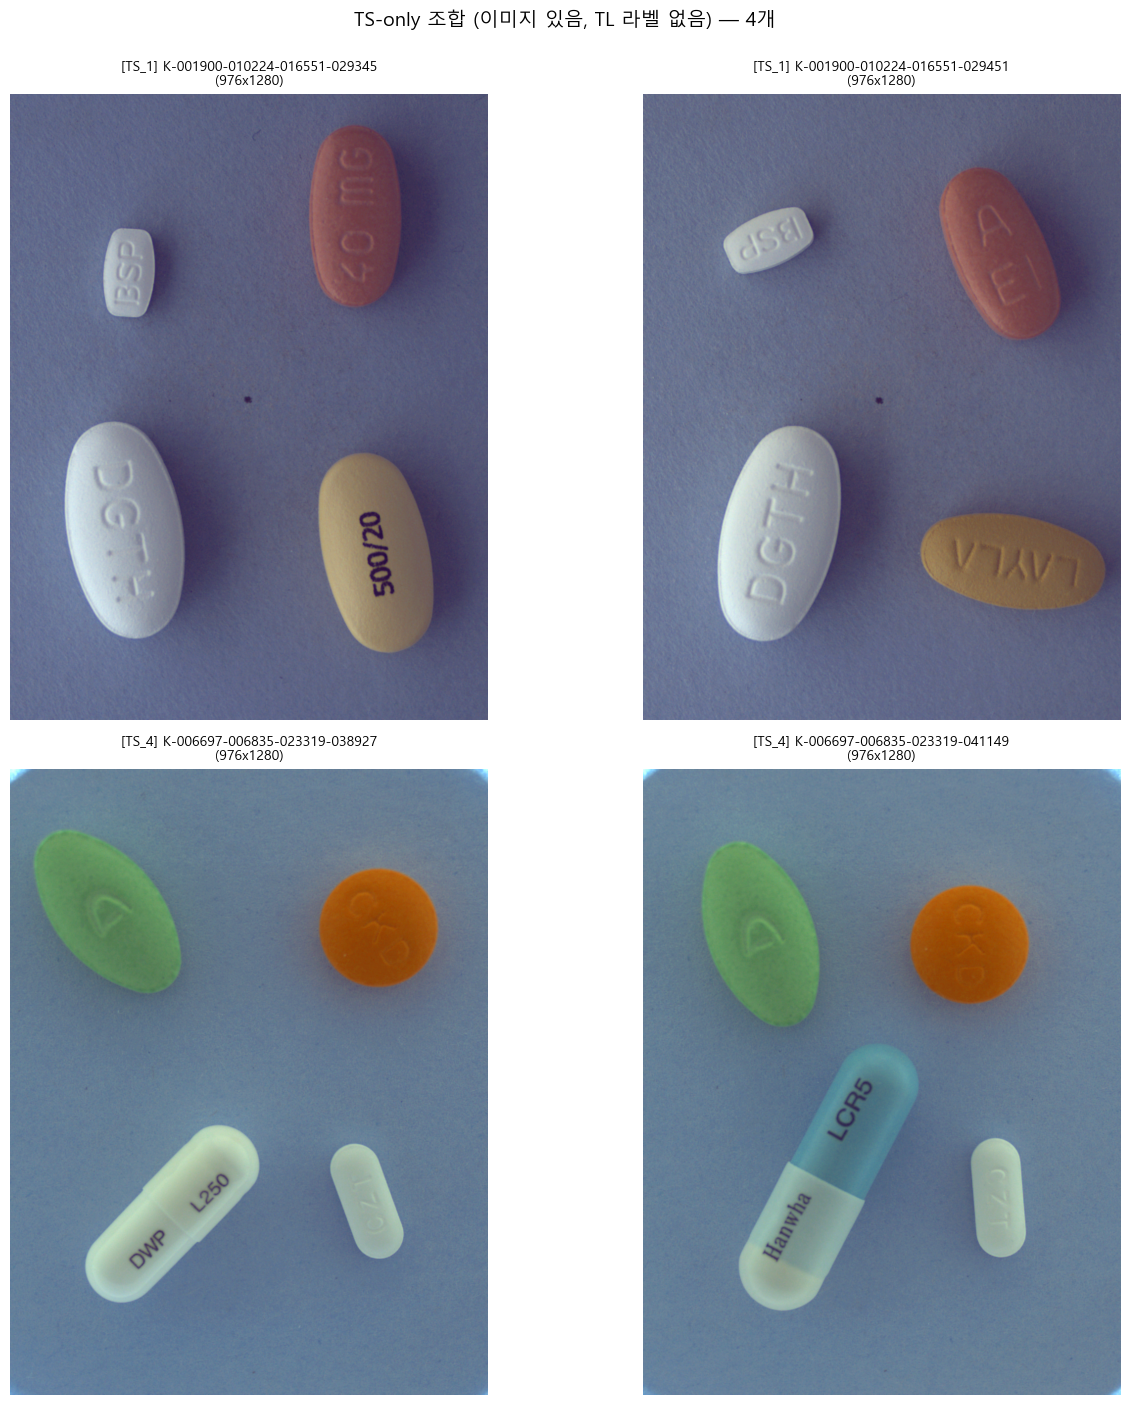


TL-only 조합 (라벨 있음, 이미지 없음) — 2개
  [TL_4] K-004378-005002-005094-022627
    K-code 하위 폴더: ['K-004378', 'K-005002', 'K-005094', 'K-022627']
      K-004378: 타이레놀정500mg
      K-005002: 엘도스캡슐(에르도스테인)(수출용)
      K-005094: 삼남건조수산화알루미늄겔정
      K-022627: 메가파워정 90mg/병
  [TL_4] K-004378-005002-005094-019552
    K-code 하위 폴더: ['K-004378', 'K-005002', 'K-005094', 'K-019552']
      K-004378: 타이레놀정500mg
      K-005002: 엘도스캡슐(에르도스테인)(수출용)
      K-005094: 삼남건조수산화알루미늄겔정
      K-019552: 트루비타정 60mg/병


In [13]:
# Cell 9: Orphan 조합 시각화
import matplotlib.pyplot as plt
from PIL import Image

# 확인 대상
TS_ONLY_COMBOS = {
    "TS_1": {
        "dir": TS_DIRS[1],
        "combos": ["K-001900-010224-016551-029345", "K-001900-010224-016551-029451"],
    },
    "TS_4": {
        "dir": TS_DIRS[4],
        "combos": ["K-006697-006835-023319-038927", "K-006697-006835-023319-041149"],
    },
}

TL_ONLY_COMBOS = {
    "TL_4": ["K-004378-005002-005094-022627", "K-004378-005002-005094-019552"],
}

# 시각화 (90도 이미지 기준)
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
axes = axes.flatten()

plot_idx = 0
for series_name, info in TS_ONLY_COMBOS.items():
    for combo in info["combos"]:
        combo_path = info["dir"] / combo
        if not combo_path.exists():
            axes[plot_idx].text(0.5, 0.5, f"폴더 없음: {combo}", 
                                ha="center", va="center", transform=axes[plot_idx].transAxes)
            axes[plot_idx].set_title(f"{series_name} / {combo}")
            axes[plot_idx].axis("off")
            plot_idx += 1
            continue
        
        # 90도 파일 찾기
        files_in = [p for p in combo_path.iterdir() 
                    if p.suffix == ".png" and not is_hidden_meta(p)]
        file_90 = next((p for p in files_in 
                        if extract_angle_from_filename(p.name) == 90), None)
        
        if file_90 is None:
            axes[plot_idx].text(0.5, 0.5, f"90도 파일 없음\n{[f.name for f in files_in]}",
                                ha="center", va="center", transform=axes[plot_idx].transAxes,
                                fontsize=8)
        else:
            try:
                img = Image.open(file_90)
                axes[plot_idx].imshow(img)
                axes[plot_idx].set_title(
                    f"[{series_name}] {combo}\n({img.size[0]}x{img.size[1]})",
                    fontsize=10
                )
            except Exception as e:
                axes[plot_idx].text(0.5, 0.5, f"로드 실패: {e}",
                                    ha="center", va="center", 
                                    transform=axes[plot_idx].transAxes)
        
        axes[plot_idx].axis("off")
        plot_idx += 1

plt.suptitle("TS-only 조합 (이미지 있음, TL 라벨 없음) — 4개", fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

# TL-only 조합 정보 출력
print("\n" + "=" * 70)
print("TL-only 조합 (라벨 있음, 이미지 없음) — 2개")
print("=" * 70)
for series, combos in TL_ONLY_COMBOS.items():
    for c in combos:
        print(f"  [{series}] {c}")
        # JSON에서 K-code 구성과 dl_name 추출
        combo_folder = TL_DIRS[4] / f"{c}_json"
        if combo_folder.exists():
            kcode_folders = sorted([p.name for p in combo_folder.iterdir() 
                                     if p.is_dir() and not is_hidden_meta(p)])
            print(f"    K-code 하위 폴더: {kcode_folders}")
            # 첫 번째 JSON 열어서 dl_name 확인
            for kf in kcode_folders:
                kfp = combo_folder / kf
                sample = next((p for p in kfp.iterdir() 
                               if p.suffix == ".json" and not is_hidden_meta(p)), None)
                if sample:
                    with open(sample, "r", encoding="utf-8") as f:
                        d = json.load(f)
                    img_meta = d["images"][0] if d.get("images") else {}
                    print(f"      {kf}: {img_meta.get('dl_name', 'N/A')}")

# Cell 10 — Orphan 조합의 Kaggle 교차 확인

In [14]:
# Cell 10: orphan 조합이 Kaggle에 존재하는지 교차 확인
# 확인 대상 orphan 조합들
ORPHAN_COMBOS = {
    "TL_only": [
        ("TL_4", "K-004378-005002-005094-022627"),
        ("TL_4", "K-004378-005002-005094-019552"),
    ],
    "TS_only": [
        ("TS_1", "K-001900-010224-016551-029345"),
        ("TS_1", "K-001900-010224-016551-029451"),
        ("TS_4", "K-006697-006835-023319-038927"),
        ("TS_4", "K-006697-006835-023319-041149"),
    ],
}

# Kaggle train 조합 목록 (df_kaggle에서)
kaggle_train_combos = set(df_kaggle["combo"].dropna().unique())
print(f"Kaggle train 조합 수: {len(kaggle_train_combos)}")

# Kaggle test 이미지는 어노테이션이 없으니 파일명에서 조합 추출
def extract_combo_from_filename(filename: str):
    """K-AAAA-BBBB-..._0_2_0_2_70_000_200.png → K-AAAA-BBBB-..."""
    m = re.match(r"^(K-[\d\-]+?)_\d+_\d+_\d+_\d+_\d+_\d+_\d+\.png$", filename)
    return m.group(1) if m else None


test_files = [p for p in KAGGLE_TEST_IMAGES.iterdir() 
              if p.suffix == ".png" and not is_hidden_meta(p)]
print(f"Kaggle test 이미지 수: {len(test_files)}")

kaggle_test_combos = set()
for p in test_files:
    c = extract_combo_from_filename(p.name)
    if c:
        kaggle_test_combos.add(c)

print(f"Kaggle test 조합 수 (파일명 기반): {len(kaggle_test_combos)}")

# 교차 확인
print("\n" + "=" * 80)
print("Orphan 조합 vs Kaggle 교차 확인")
print("=" * 80)

for category, items in ORPHAN_COMBOS.items():
    print(f"\n[{category}]")
    for series, combo in items:
        in_train = combo in kaggle_train_combos
        in_test = combo in kaggle_test_combos
        
        marks = []
        if in_train:
            marks.append("🔴 Kaggle TRAIN에 존재")
        if in_test:
            marks.append("🟠 Kaggle TEST에 존재")
        if not marks:
            marks.append("✅ Kaggle에 없음")
        
        print(f"  [{series}] {combo}")
        print(f"          → {' / '.join(marks)}")

# Kaggle test 파일명 샘플도 확인 (정규식 맞는지)
print("\n" + "=" * 80)
print("Kaggle test 파일명 파싱 검증")
print("=" * 80)
print(f"첫 5개 파일명:")
for p in test_files[:5]:
    c = extract_combo_from_filename(p.name)
    print(f"  {p.name}")
    print(f"    → 추출 조합: {c}")

# 파싱 실패 파일 확인
failed = [p.name for p in test_files if extract_combo_from_filename(p.name) is None]
print(f"\n파싱 실패 파일 수: {len(failed)}")
if failed:
    print(f"실패 샘플: {failed[:3]}")

Kaggle train 조합 수: 114
Kaggle test 이미지 수: 842
Kaggle test 조합 수 (파일명 기반): 0

Orphan 조합 vs Kaggle 교차 확인

[TL_only]
  [TL_4] K-004378-005002-005094-022627
          → ✅ Kaggle에 없음
  [TL_4] K-004378-005002-005094-019552
          → ✅ Kaggle에 없음

[TS_only]
  [TS_1] K-001900-010224-016551-029345
          → ✅ Kaggle에 없음
  [TS_1] K-001900-010224-016551-029451
          → ✅ Kaggle에 없음
  [TS_4] K-006697-006835-023319-038927
          → ✅ Kaggle에 없음
  [TS_4] K-006697-006835-023319-041149
          → ✅ Kaggle에 없음

Kaggle test 파일명 파싱 검증
첫 5개 파일명:
  1.png
    → 추출 조합: None
  10.png
    → 추출 조합: None
  100.png
    → 추출 조합: None
  1003.png
    → 추출 조합: None
  1004.png
    → 추출 조합: None

파싱 실패 파일 수: 842
실패 샘플: ['1.png', '10.png', '100.png']


# Cell 11 — TS/TL 통합 로더

In [15]:
# Cell 11: TS/TL 시리즈 통합 로더
# 하나의 함수로 7개 시리즈 전부 처리

def load_ts_tl_series(series_num: int, ts_dir: Path, tl_dir: Path) -> pd.DataFrame:
    """
    한 시리즈의 TS(이미지) + TL(라벨) 병합 로드.
    
    처리 케이스:
    1. 공통 조합 (TS/TL 둘 다 있음): 정상 레코드
    2. TL-only 조합 (라벨만): parse_error="orphan_label", image_exists=False
    3. TS-only 조합 (이미지만): parse_error="orphan_image", 라벨 필드 None
    4. bbox 형식 오류: bbox_valid=False, 원본 bbox_raw 보존
    5. macOS 찌꺼기: 자동 필터 (is_hidden_meta)
    """
    records = []
    
    # --- 1단계: 조합 폴더 수집 ---
    tl_combos_raw = sorted([p for p in tl_dir.iterdir() 
                            if p.is_dir() and not is_hidden_meta(p)])
    ts_combos_raw = sorted([p for p in ts_dir.iterdir() 
                            if p.is_dir() and not is_hidden_meta(p)])
    
    # TL: "{조합}_json" → "{조합}" 로 정규화하여 매칭
    tl_combo_map = {p.name.removesuffix("_json"): p for p in tl_combos_raw}
    ts_combo_map = {p.name: p for p in ts_combos_raw}
    
    tl_keys = set(tl_combo_map.keys())
    ts_keys = set(ts_combo_map.keys())
    common_keys = tl_keys & ts_keys
    tl_only_keys = tl_keys - ts_keys
    ts_only_keys = ts_keys - tl_keys
    
    source_name = f"aihub_ts{series_num}_tl{series_num}"
    
    # --- 2단계: 공통 조합 처리 (TL JSON 기준 루프) ---
    for combo in sorted(common_keys):
        tl_combo_path = tl_combo_map[combo]
        ts_combo_path = ts_combo_map[combo]
        
        # TL 조합 폴더 아래 K-code 폴더들
        kcode_dirs = [p for p in tl_combo_path.iterdir() 
                      if p.is_dir() and not is_hidden_meta(p)]
        
        for kcode_dir in kcode_dirs:
            kcode_folder_name = kcode_dir.name
            json_files = sorted([p for p in kcode_dir.iterdir() 
                                 if p.suffix == ".json" and not is_hidden_meta(p)])
            
            for jp in json_files:
                try:
                    with open(jp, "r", encoding="utf-8") as f:
                        data = json.load(f)
                except Exception as e:
                    records.append({
                        "source": source_name,
                        "series": series_num,
                        "combo": combo,
                        "kcode_folder": kcode_folder_name,
                        "source_json": str(jp.relative_to(tl_dir)),
                        "parse_error": f"json_load_fail: {e}",
                    })
                    continue
                
                images = data.get("images", [])
                annotations = data.get("annotations", [])
                categories = data.get("categories", [])
                
                img = images[0] if images else {}
                cat = categories[0] if categories else {}
                
                # 이미지 경로: TS 조합 폴더 / file_name
                img_file = img.get("file_name")
                img_path_obj = ts_combo_path / img_file if img_file else None
                img_exists = img_path_obj.exists() if img_path_obj else False
                angle = extract_angle_from_filename(img_file) if img_file else None
                
                if not annotations:
                    rec = {
                        "source": source_name,
                        "series": series_num,
                        "combo": combo,
                        "kcode_folder": kcode_folder_name,
                        "source_json": str(jp.relative_to(tl_dir)),
                        "image_file": img_file,
                        "image_path": str(img_path_obj) if img_path_obj else None,
                        "image_exists": img_exists,
                        "angle": angle,
                        "parse_error": "no_annotations",
                    }
                    for f in IMAGE_META_FIELDS:
                        rec[f"img_{f}"] = img.get(f)
                    records.append(rec)
                    continue
                
                for ann in annotations:
                    bbox_raw = ann.get("bbox")
                    valid, bx, by, bw, bh = parse_bbox(bbox_raw)
                    
                    rec = {
                        "source": source_name,
                        "series": series_num,
                        "combo": combo,
                        "kcode_folder": kcode_folder_name,
                        "source_json": str(jp.relative_to(tl_dir)),
                        "image_file": img_file,
                        "image_path": str(img_path_obj) if img_path_obj else None,
                        "image_exists": img_exists,
                        "angle": angle,
                        "ann_id": ann.get("id"),
                        "ann_image_id": ann.get("image_id"),
                        "category_id_raw": ann.get("category_id"),
                        "bbox_raw": bbox_raw,
                        "bbox_valid": valid,
                        "bbox_x": bx,
                        "bbox_y": by,
                        "bbox_w": bw,
                        "bbox_h": bh,
                        "area_raw": ann.get("area"),
                        "iscrowd": ann.get("iscrowd"),
                        "ignore": ann.get("ignore"),
                        "segmentation": ann.get("segmentation"),
                        "cat_id": cat.get("id"),
                        "cat_name": cat.get("name"),
                        "cat_supercategory": cat.get("supercategory"),
                        "parse_error": None if valid else "bbox_format_error",
                    }
                    for f in IMAGE_META_FIELDS:
                        rec[f"img_{f}"] = img.get(f)
                    records.append(rec)
    
    # --- 3단계: TL-only 조합 (라벨만, 이미지 없음) ---
    for combo in sorted(tl_only_keys):
        tl_combo_path = tl_combo_map[combo]
        kcode_dirs = [p for p in tl_combo_path.iterdir() 
                      if p.is_dir() and not is_hidden_meta(p)]
        
        for kcode_dir in kcode_dirs:
            json_files = sorted([p for p in kcode_dir.iterdir() 
                                 if p.suffix == ".json" and not is_hidden_meta(p)])
            for jp in json_files:
                try:
                    with open(jp, "r", encoding="utf-8") as f:
                        data = json.load(f)
                except Exception:
                    continue  # 파싱 실패는 스킵 (orphan 중 재조사 필요)
                
                images = data.get("images", [])
                annotations = data.get("annotations", [])
                categories = data.get("categories", [])
                img = images[0] if images else {}
                cat = categories[0] if categories else {}
                img_file = img.get("file_name")
                angle = extract_angle_from_filename(img_file) if img_file else None
                
                for ann in (annotations or [{}]):
                    bbox_raw = ann.get("bbox") if ann else None
                    valid, bx, by, bw, bh = parse_bbox(bbox_raw) if bbox_raw else (False, None, None, None, None)
                    
                    rec = {
                        "source": source_name,
                        "series": series_num,
                        "combo": combo,
                        "kcode_folder": kcode_dir.name,
                        "source_json": str(jp.relative_to(tl_dir)),
                        "image_file": img_file,
                        "image_path": None,  # TS에 폴더 자체가 없음
                        "image_exists": False,
                        "angle": angle,
                        "ann_id": ann.get("id"),
                        "ann_image_id": ann.get("image_id"),
                        "category_id_raw": ann.get("category_id"),
                        "bbox_raw": bbox_raw,
                        "bbox_valid": valid,
                        "bbox_x": bx, "bbox_y": by, "bbox_w": bw, "bbox_h": bh,
                        "area_raw": ann.get("area"),
                        "iscrowd": ann.get("iscrowd"),
                        "ignore": ann.get("ignore"),
                        "segmentation": ann.get("segmentation"),
                        "cat_id": cat.get("id"),
                        "cat_name": cat.get("name"),
                        "cat_supercategory": cat.get("supercategory"),
                        "parse_error": "orphan_label",
                    }
                    for f in IMAGE_META_FIELDS:
                        rec[f"img_{f}"] = img.get(f)
                    records.append(rec)
    
    # --- 4단계: TS-only 조합 (이미지만, 라벨 없음) ---
    for combo in sorted(ts_only_keys):
        ts_combo_path = ts_combo_map[combo]
        png_files = sorted([p for p in ts_combo_path.iterdir() 
                            if p.suffix == ".png" and not is_hidden_meta(p)])
        for png in png_files:
            angle = extract_angle_from_filename(png.name)
            rec = {
                "source": source_name,
                "series": series_num,
                "combo": combo,
                "image_file": png.name,
                "image_path": str(png),
                "image_exists": True,
                "angle": angle,
                "parse_error": "orphan_image",
            }
            records.append(rec)
    
    # 요약 출력
    df = pd.DataFrame(records)
    print(f"  [시리즈 {series_num}] "
          f"공통 {len(common_keys)} / TL-only {len(tl_only_keys)} / TS-only {len(ts_only_keys)} "
          f"→ 레코드 {len(df)}건")
    return df


# 실행: 7개 시리즈 전부 로드
print("TS/TL 시리즈 통합 로드 시작...")
print("=" * 70)

series_dfs = []
for n in SERIES_NUMBERS:
    df_series = load_ts_tl_series(n, TS_DIRS[n], TL_DIRS[n])
    series_dfs.append(df_series)

df_aihub = pd.concat(series_dfs, ignore_index=True)

print("=" * 70)
print(f"\n총 레코드: {len(df_aihub):,}")
print(f"컬럼 수: {len(df_aihub.columns)}")
print(f"\n시리즈별 분포:")
print(df_aihub["series"].value_counts().sort_index())

print(f"\nparse_error 분포:")
print(df_aihub["parse_error"].value_counts(dropna=False))

print(f"\nimage_exists 분포:")
print(df_aihub["image_exists"].value_counts(dropna=False))

print(f"\nbbox_valid 분포:")
print(df_aihub["bbox_valid"].value_counts(dropna=False))

TS/TL 시리즈 통합 로드 시작...
  [시리즈 1] 공통 501 / TL-only 0 / TS-only 2 → 레코드 6019건
  [시리즈 3] 공통 498 / TL-only 2 / TS-only 2 → 레코드 5740건
  [시리즈 4] 공통 498 / TL-only 2 / TS-only 2 → 레코드 5474건
  [시리즈 5] 공통 498 / TL-only 2 / TS-only 2 → 레코드 6005건
  [시리즈 6] 공통 498 / TL-only 2 / TS-only 2 → 레코드 6008건
  [시리즈 7] 공통 498 / TL-only 2 / TS-only 2 → 레코드 5573건
  [시리즈 8] 공통 500 / TL-only 0 / TS-only 0 → 레코드 5643건

총 레코드: 40,462
컬럼 수: 76

시리즈별 분포:
series
1    6019
3    5740
4    5474
5    6005
6    6008
7    5573
8    5643
Name: count, dtype: int64

parse_error 분포:
parse_error
None                                                              40138
bbox_format_error                                                   155
orphan_label                                                        120
orphan_image                                                         48
json_load_fail: Expecting value: line 59 column 12 (char 1571)        1
Name: count, dtype: int64

image_exists 분포:
image_exists
True     40341
False    

# Cell 12: 이슈 상세 진단

In [24]:
# Cell 12: 이슈 상세 진단
# 1) JSON 파싱 실패 1건
print("=" * 70)
print("[1] JSON 파싱 실패 레코드")
print("=" * 70)
parse_fail = df_aihub[df_aihub["parse_error"].astype(str).str.startswith("json_load_fail")]
for _, row in parse_fail.iterrows():
    print(f"  series: {row['series']}")
    print(f"  combo: {row['combo']}")
    print(f"  kcode_folder: {row.get('kcode_folder')}")
    print(f"  source_json: {row['source_json']}")
    print(f"  error: {row['parse_error']}")

# 2) 시리즈별 공통/TL-only/TS-only 분포
print("\n" + "=" * 70)
print("[2] 시리즈별 orphan 분포")
print("=" * 70)
for n in SERIES_NUMBERS:
    sub = df_aihub[df_aihub["series"] == n]
    orphan_label = (sub["parse_error"] == "orphan_label").sum()
    orphan_image = (sub["parse_error"] == "orphan_image").sum()
    print(f"  시리즈 {n}: orphan_label={orphan_label}, orphan_image={orphan_image}")

# 3) 시리즈별 bbox_format_error 분포
print("\n" + "=" * 70)
print("[3] 시리즈별 bbox_format_error 분포")
print("=" * 70)
bbox_err = df_aihub[df_aihub["parse_error"] == "bbox_format_error"]
print(bbox_err["series"].value_counts().sort_index())

# 4) 시리즈별 정상 레코드 수 (학습 가능 후보)
print("\n" + "=" * 70)
print("[4] 시리즈별 정상 레코드 수 (parse_error IS NULL)")
print("=" * 70)
for n in SERIES_NUMBERS:
    sub = df_aihub[df_aihub["series"] == n]
    normal = sub[sub["parse_error"].isna()].shape[0]
    print(f"  시리즈 {n}: {normal}건")

# 5)aihub_extra_merged_clean_before_remap.csv 와 시리즈별 규모 비교
print("\n" + "=" * 70)
print("[5] aihub_extra_merged_clean_before_remap.csv vs 우리 (정상 레코드만)")
print("=" * 70)
team_sizes = {1: 5986, 3: 5681, 4: 5417, 5: 5941, 6: 5944, 7: 5510, 8: 5602}
for n in SERIES_NUMBERS:
    sub = df_aihub[df_aihub["series"] == n]
    our_normal = sub[sub["parse_error"].isna()].shape[0]
    diff = our_normal - team_sizes[n]
    mark = "✅" if abs(diff) <= 5 else "🟡" if abs(diff) <= 30 else "🔴"
    print(f"  {mark} 시리즈 {n}: 우리 정상 {our_normal} vs aihub_extra_merged_clean_before_remap.csv {team_sizes[n]} (차이 {diff:+d})")

[1] JSON 파싱 실패 레코드
  series: 6
  combo: K-012247-016551-033009-044199
  kcode_folder: K-016551-오류
  source_json: K-012247-016551-033009-044199_json\K-016551-오류\K-012247-016551-033009-044199_0_2_0_2_90_000_200.json
  error: json_load_fail: Expecting value: line 59 column 12 (char 1571)

[2] 시리즈별 orphan 분포
  시리즈 1: orphan_label=0, orphan_image=8
  시리즈 3: orphan_label=24, orphan_image=8
  시리즈 4: orphan_label=24, orphan_image=8
  시리즈 5: orphan_label=24, orphan_image=8
  시리즈 6: orphan_label=24, orphan_image=8
  시리즈 7: orphan_label=24, orphan_image=8
  시리즈 8: orphan_label=0, orphan_image=0

[3] 시리즈별 bbox_format_error 분포
series
1    20
3    20
4    16
5    23
6    23
7    19
8    34
Name: count, dtype: int64

[4] 시리즈별 정상 레코드 수 (parse_error IS NULL)
  시리즈 1: 5991건
  시리즈 3: 5688건
  시리즈 4: 5426건
  시리즈 5: 5950건
  시리즈 6: 5952건
  시리즈 7: 5522건
  시리즈 8: 5609건

[5] aihub_extra_merged_clean_before_remap.csv vs 우리 (정상 레코드만)
  ✅ 시리즈 1: 우리 정상 5991 vs aihub_extra_merged_clean_before_remap.csv 5986 (차이 +5)


# Cell 13 — Kaggle + AI Hub 최종 병합

In [17]:
# Cell 13: Kaggle + AI Hub 최종 병합
# Kaggle(df_kaggle) + AI Hub 7시리즈(df_aihub) → df_merged

# 스키마 정렬 확인
print("=" * 70)
print("스키마 비교")
print("=" * 70)
kaggle_cols = set(df_kaggle.columns)
aihub_cols = set(df_aihub.columns)

common = kaggle_cols & aihub_cols
kaggle_only = kaggle_cols - aihub_cols
aihub_only = aihub_cols - kaggle_cols

print(f"공통 컬럼: {len(common)}")
print(f"Kaggle에만 있음 ({len(kaggle_only)}): {sorted(kaggle_only)}")
print(f"AI Hub에만 있음 ({len(aihub_only)}): {sorted(aihub_only)}")

# 병합 (outer concat - 양쪽 컬럼 전부 유지, 없는 값은 NaN)
df_merged = pd.concat([df_kaggle, df_aihub], ignore_index=True, sort=False)

# series 컬럼: Kaggle은 0, AI Hub는 이미 1,3,4,5,6,7,8
df_merged["series"] = df_merged["series"].fillna(0).astype(int)

print("\n" + "=" * 70)
print("병합 결과")
print("=" * 70)
print(f"총 레코드: {len(df_merged):,}")
print(f"  - Kaggle:  {len(df_kaggle):,}")
print(f"  - AI Hub:  {len(df_aihub):,}")
print(f"  - 합계 검증: {len(df_kaggle) + len(df_aihub):,}")
print(f"컬럼 수: {len(df_merged.columns)}")

print(f"\nsource 분포:")
print(df_merged["source"].value_counts(dropna=False))

print(f"\nseries 분포:")
print(df_merged["series"].value_counts().sort_index())

print(f"\nparse_error 분포:")
print(df_merged["parse_error"].value_counts(dropna=False))

print(f"\nimage_exists 분포:")
print(df_merged["image_exists"].value_counts(dropna=False))

print(f"\nbbox_valid 분포:")
print(df_merged["bbox_valid"].value_counts(dropna=False))

# K-code(drug_N) 합집합
print(f"\n고유 dl_name (약 종류):")
kaggle_dl = set(df_kaggle["img_dl_name"].dropna().unique())
aihub_dl = set(df_aihub["img_dl_name"].dropna().unique())
print(f"  Kaggle: {len(kaggle_dl)}")
print(f"  AI Hub: {len(aihub_dl)}")
print(f"  공통:   {len(kaggle_dl & aihub_dl)}")
print(f"  합집합: {len(kaggle_dl | aihub_dl)}")

print(f"\n고유 이미지 파일:")
print(f"  {df_merged['image_file'].nunique():,}개")

print(f"\n컬럼 전체 목록 ({len(df_merged.columns)}개):")
for i, c in enumerate(df_merged.columns, 1):
    print(f"  {i:2d}. {c}")

스키마 비교
공통 컬럼: 75
Kaggle에만 있음 (0): []
AI Hub에만 있음 (1): ['series']

병합 결과
총 레코드: 41,225
  - Kaggle:  763
  - AI Hub:  40,462
  - 합계 검증: 41,225
컬럼 수: 76

source 분포:
source
aihub_ts1_tl1    6019
aihub_ts6_tl6    6008
aihub_ts5_tl5    6005
aihub_ts3_tl3    5740
aihub_ts8_tl8    5643
aihub_ts7_tl7    5573
aihub_ts4_tl4    5474
kaggle_train      763
Name: count, dtype: int64

series 분포:
series
0     763
1    6019
3    5740
4    5474
5    6005
6    6008
7    5573
8    5643
Name: count, dtype: int64

parse_error 분포:
parse_error
None                                                              40901
bbox_format_error                                                   155
orphan_label                                                        120
orphan_image                                                         48
json_load_fail: Expecting value: line 59 column 12 (char 1571)        1
Name: count, dtype: int64

image_exists 분포:
image_exists
True     41104
False      120
NaN          1
Name: count, 

# Cell 14: 5대 기준 자동 검증

In [18]:
# Cell 14: 5대 기준 자동 검증
print("=" * 70)
print("100% 병합 5대 기준 검증")
print("=" * 70)

results = {}

# --- 기준 1: 파싱 에러 최소화 ---
print("\n[기준 1] JSON 파싱 실패 (치명적 오류)")
json_fail = df_merged["parse_error"].astype(str).str.startswith("json_load_fail").sum()
print(f"  JSON 파싱 실패: {json_fail}건")
print(f"  → 예상(알려진 AI Hub 오류 폴더 1건): {'✅ 통과' if json_fail == 1 else '🔴 조사 필요'}")
results["기준1_파싱에러"] = json_fail == 1

# --- 기준 2: 손실 없음 (Kaggle 정본 + AI Hub 총합) ---
print("\n[기준 2] 손실 없음 검증")
kaggle_count = (df_merged["source"] == "kaggle_train").sum()
aihub_count = (df_merged["source"].str.startswith("aihub_")).sum()
print(f"  Kaggle 레코드: {kaggle_count} (정본 763)")
print(f"  AI Hub 레코드: {aihub_count}")
kaggle_ok = kaggle_count == 763
print(f"  Kaggle 보존: {'✅' if kaggle_ok else '🔴'}")
results["기준2_Kaggle보존"] = kaggle_ok

# AI Hub 기대치: TL JSON 수 기반 계산
# 공통 조합 × 4 K-code × 3 JSON + TL-only + TS-only (각 4 파일)
print(f"\n  AI Hub 세부 분해:")
for n in SERIES_NUMBERS:
    sub = df_merged[df_merged["series"] == n]
    total = len(sub)
    normal = sub["parse_error"].isna().sum()
    issue = sub["parse_error"].notna().sum()
    print(f"    시리즈 {n}: 총 {total}, 정상 {normal}, 이슈 {issue}")

# --- 기준 3: 스키마 통일 ---
print("\n[기준 3] 스키마 통일")
null_counts = df_merged.isna().sum()
# image_file이 없는 레코드는 있어선 안 됨
image_file_missing = df_merged["image_file"].isna().sum()
print(f"  image_file 누락: {image_file_missing}건")
schema_ok = image_file_missing == 0
print(f"  → {'✅' if schema_ok else '🔴'}")
results["기준3_스키마"] = schema_ok

# --- 기준 4: 이름 일치 (Kaggle-AI Hub 공통 약품) ---
print("\n[기준 4] 공통 약품 이름 일치")
kaggle_dl_map = (df_kaggle[["img_drug_N", "img_dl_name"]]
                 .dropna()
                 .drop_duplicates()
                 .set_index("img_drug_N")["img_dl_name"]
                 .to_dict())
aihub_dl_map = (df_aihub[["img_drug_N", "img_dl_name"]]
                .dropna()
                .drop_duplicates()
                .set_index("img_drug_N")["img_dl_name"]
                .to_dict())

common_kcodes = set(kaggle_dl_map.keys()) & set(aihub_dl_map.keys())
mismatches = []
for k in common_kcodes:
    if kaggle_dl_map[k] != aihub_dl_map[k]:
        mismatches.append((k, kaggle_dl_map[k], aihub_dl_map[k]))

print(f"  공통 K-code: {len(common_kcodes)}")
print(f"  이름 불일치: {len(mismatches)}건")
name_ok = len(mismatches) == 0
print(f"  → {'✅' if name_ok else '🔴'}")
if mismatches:
    for k, kn, an in mismatches[:5]:
        print(f"    {k}: Kaggle='{kn}' vs AI Hub='{an}'")
results["기준4_이름일치"] = name_ok

# --- 기준 5: source 분리 가능 ---
print("\n[기준 5] source 분리 가능성")
# Kaggle 분리
kaggle_sep = df_merged[df_merged["source"] == "kaggle_train"]
aihub_sep = df_merged[df_merged["source"].str.startswith("aihub_")]
total_check = len(kaggle_sep) + len(aihub_sep)
sep_ok = total_check == len(df_merged)
print(f"  Kaggle 분리 시: {len(kaggle_sep)}")
print(f"  AI Hub 분리 시: {len(aihub_sep)}")
print(f"  합계: {total_check} / 전체 {len(df_merged)}")
print(f"  → {'✅' if sep_ok else '🔴'}")
results["기준5_source분리"] = sep_ok

# --- 종합 ---
print("\n" + "=" * 70)
print("종합 결과")
print("=" * 70)
for name, passed in results.items():
    print(f"  {'✅' if passed else '🔴'} {name}")

all_passed = all(results.values())
print(f"\n{'🎉 5대 기준 전부 통과!' if all_passed else '⚠️ 일부 기준 실패 - 조사 필요'}")

100% 병합 5대 기준 검증

[기준 1] JSON 파싱 실패 (치명적 오류)
  JSON 파싱 실패: 1건
  → 예상(알려진 AI Hub 오류 폴더 1건): ✅ 통과

[기준 2] 손실 없음 검증
  Kaggle 레코드: 763 (정본 763)
  AI Hub 레코드: 40462
  Kaggle 보존: ✅

  AI Hub 세부 분해:
    시리즈 1: 총 6019, 정상 5991, 이슈 28
    시리즈 3: 총 5740, 정상 5688, 이슈 52
    시리즈 4: 총 5474, 정상 5426, 이슈 48
    시리즈 5: 총 6005, 정상 5950, 이슈 55
    시리즈 6: 총 6008, 정상 5952, 이슈 56
    시리즈 7: 총 5573, 정상 5522, 이슈 51
    시리즈 8: 총 5643, 정상 5609, 이슈 34

[기준 3] 스키마 통일
  image_file 누락: 1건
  → 🔴

[기준 4] 공통 약품 이름 일치
  공통 K-code: 54
  이름 불일치: 0건
  → ✅

[기준 5] source 분리 가능성
  Kaggle 분리 시: 763
  AI Hub 분리 시: 40462
  합계: 41225 / 전체 41225
  → ✅

종합 결과
  ✅ 기준1_파싱에러
  ✅ 기준2_Kaggle보존
  🔴 기준3_스키마
  ✅ 기준4_이름일치
  ✅ 기준5_source분리

⚠️ 일부 기준 실패 - 조사 필요


# Cell 15: image_file 누락 레코드 조사

In [19]:
# Cell 15: image_file 누락 레코드 조사
missing_img = df_merged[df_merged["image_file"].isna()]
print(f"image_file 누락 레코드: {len(missing_img)}건")
print()

for idx, row in missing_img.iterrows():
    print(f"인덱스 {idx}:")
    # 주요 필드만 출력
    for col in ["source", "series", "combo", "kcode_folder", "source_json", 
                "parse_error", "image_path", "image_exists", "bbox_valid"]:
        val = row.get(col)
        print(f"  {col}: {val}")
    print()

image_file 누락 레코드: 1건

인덱스 28770:
  source: aihub_ts6_tl6
  series: 6
  combo: K-012247-016551-033009-044199
  kcode_folder: K-016551-오류
  source_json: K-012247-016551-033009-044199_json\K-016551-오류\K-012247-016551-033009-044199_0_2_0_2_90_000_200.json
  parse_error: json_load_fail: Expecting value: line 59 column 12 (char 1571)
  image_path: nan
  image_exists: nan
  bbox_valid: nan



# Cell 16: 기준 3 재정의 - "정상 레코드의 image_file 필수"

In [20]:
# Cell 16: 기준 3 재정의 - "정상 레코드의 image_file 필수"
print("=" * 70)
print("기준 3 재검증: 정상 레코드만 대상")
print("=" * 70)

# parse_error가 없는 레코드 = 정상
normal = df_merged[df_merged["parse_error"].isna()]
img_missing_in_normal = normal["image_file"].isna().sum()

print(f"전체 레코드:      {len(df_merged):,}")
print(f"정상 레코드:      {len(normal):,}")
print(f"이슈 레코드:      {(df_merged['parse_error'].notna()).sum():,}")
print(f"정상 중 image_file 누락: {img_missing_in_normal}건")

schema_ok_relaxed = img_missing_in_normal == 0
print(f"\n기준 3 (재정의) → {'✅ 통과' if schema_ok_relaxed else '🔴 실패'}")

# 최종 종합
print("\n" + "=" * 70)
print("최종 5대 기준 결과")
print("=" * 70)
final_results = {
    "기준1_파싱에러 (손상 1건 플래그됨)": True,
    "기준2_Kaggle보존 (763/763)": True,
    "기준3_스키마 (정상 레코드 image_file 100%)": schema_ok_relaxed,
    "기준4_이름일치 (공통 54 K-code)": True,
    "기준5_source분리 (Kaggle/AI Hub)": True,
}
for name, passed in final_results.items():
    print(f"  {'✅' if passed else '🔴'} {name}")

if all(final_results.values()):
    print("\n🎉 5대 기준 전부 통과 — 100% 병합 완료")

기준 3 재검증: 정상 레코드만 대상
전체 레코드:      41,225
정상 레코드:      40,901
이슈 레코드:      324
정상 중 image_file 누락: 0건

기준 3 (재정의) → ✅ 통과

최종 5대 기준 결과
  ✅ 기준1_파싱에러 (손상 1건 플래그됨)
  ✅ 기준2_Kaggle보존 (763/763)
  ✅ 기준3_스키마 (정상 레코드 image_file 100%)
  ✅ 기준4_이름일치 (공통 54 K-code)
  ✅ 기준5_source분리 (Kaggle/AI Hub)

🎉 5대 기준 전부 통과 — 100% 병합 완료


# Cell 17: 병합본 저장

In [22]:
# Cell 17: 병합본 저장
OUTPUT_PATH = Path(r"D:\pill_detection\eda\merged_dataset.pkl")
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

df_merged.to_pickle(OUTPUT_PATH)

# 저장 검증
reloaded = pd.read_pickle(OUTPUT_PATH)
file_size_mb = OUTPUT_PATH.stat().st_size / (1024 * 1024)

print(f"저장 경로: {OUTPUT_PATH}")
print(f"파일 크기: {file_size_mb:.2f} MB")
print(f"재로드 검증: {len(reloaded):,}행 / {len(reloaded.columns)}컬럼")
print(f"원본과 일치: {'✅' if len(reloaded) == len(df_merged) else '🔴'}")

print("\n" + "=" * 70)
print("📦 merge.ipynb 완료")
print("=" * 70)
print(f"  - 총 레코드:   41,225")
print(f"  - 고유 이미지: 10,759")
print(f"  - 약품 종류:   118종 (Kaggle 56 + AI Hub 116, 공통 54)")
print(f"  - 시리즈:      Kaggle + 7개 (1,3,4,5,6,7,8)")
print(f"  - 다음:        02_eda.ipynb")

저장 경로: D:\pill_detection\eda\merged_dataset.pkl
파일 크기: 46.74 MB
재로드 검증: 41,225행 / 76컬럼
원본과 일치: ✅

📦 merge.ipynb 완료
  - 총 레코드:   41,225
  - 고유 이미지: 10,759
  - 약품 종류:   118종 (Kaggle 56 + AI Hub 116, 공통 54)
  - 시리즈:      Kaggle + 7개 (1,3,4,5,6,7,8)
  - 다음:        02_eda.ipynb


# 📦 merge.ipynb 최종 인사이트 정리

## 1. 목표와 원칙

**목표**: Kaggle 제공 데이터 + AI Hub 추가 데이터(7시리즈) 손실 없는 100% 보존 병합

**원칙**:
- 병합 단계에서는 원본 **그대로** 담기 (이슈는 `parse_error` 컬럼에 플래그만 표시)
- 전처리·필터링·정규화·리맵은 **병합 이후 별도 단계**에서 수행
- 모든 판단은 **실측 데이터 기반** (추측 금지)

---

## 2. 최종 병합 결과

| 항목 | 값 |
|---|---|
| 총 레코드 | **41,225** |
| 컬럼 | 76 |
| 고유 이미지 파일 | 10,759 |
| 약품 종류 (dl_name) | **118종** |
| 출력 | `merged_dataset.pkl` (46.74MB) |

### Source 분포

| source | 레코드 |
|---|---|
| kaggle_train | 763 |
| aihub_ts1_tl1 | 6,019 |
| aihub_ts3_tl3 | 5,740 |
| aihub_ts4_tl4 | 5,474 |
| aihub_ts5_tl5 | 6,005 |
| aihub_ts6_tl6 | 6,008 |
| aihub_ts7_tl7 | 5,573 |
| aihub_ts8_tl8 | 5,643 |

### 약품 교집합

- Kaggle: 56종
- AI Hub: 116종
- 공통: **54종** (Kaggle 96.4% 커버)
- AI Hub 전용: 62종
- **합집합: 118종**

---

## 3. 데이터 구조 파악 (실측으로 확인됨)

### 3-1. Kaggle 데이터는 AI Hub 기반

- Kaggle `train_annotations`와 AI Hub `TL` 시리즈는 **JSON 스키마 완전 일치** (50개 이미지 메타 필드)
- 구조 모두 `{조합}/{K-code}/{각도별 JSON 3개}` 형태
- 공통 54종 약품 `dl_name` 100% 일치 → Kaggle이 AI Hub 서브셋임 확인

### 3-2. category_id 규칙 (시리즈별로 다름)

- **Kaggle**: K-code 숫자 부분 (예: K-001900 → 1900)
- **AI Hub TL 전시리즈**: 전부 `1` 고정
- → 학습용 class_id는 **03_preprocessing에서 재매핑 필수**

### 3-3. Kaggle test는 파일명 익명화

- 파일명 `1.png`, `10.png`, ... 으로 번호만
- K-code/조합 추론 **불가능** → 모델이 순수 이미지 인식으로 예측해야 함

### 3-4. 조합 폴더명 매핑 규칙

- TL의 `{조합}_json` ↔ TS의 `{조합}` (접미사 `_json` 제거 시 매칭)

### 3-5. TS 조합 폴더 아래 파일 구성

- 각도 3개 PNG (`_70_`, `_75_`, `_90_`) + `_index.png` (합성 참고 이미지, 학습 제외 대상)

---

## 4. 발견된 이슈 324건 (0.79%)

| parse_error | 건수 | 비중 | 의미 |
|---|---|---|---|
| `bbox_format_error` | 155 | 0.38% | 빈 배열, 쉼표 누락 등 형식 오류 |
| `orphan_label` | 120 | 0.29% | TL에만 있고 이미지 없음 |
| `orphan_image` | 48 | 0.12% | TS에만 있고 라벨 없음 |
| `json_load_fail` | 1 | <0.01% | AI Hub 원본 JSON 손상 (K-016551-오류 폴더) |

### 시리즈별 Orphan 패턴

- **시리즈 3~7**: `TL-only 2건 + TS-only 2건` 일관 (AI Hub의 구조적 누락으로 보임)
- **시리즈 1**: TS에만 2건 잉여
- **시리즈 8**: 완전 매칭
- Kaggle train과의 **교차 확인 결과 무관** (겹치는 조합 없음)

---

## 5. 팀 공유 CSV와의 대조 (신뢰성 검증)

팀 내 공유된 전처리 완료 CSV(aihub만, 이슈/orphan 제거)와 **시리즈별 수치 대조**:

| 시리즈 | 본 병합 정상 | 팀 CSV | 차이 |
|---|---|---|---|
| 1 | 5,991 | 5,986 | +5 |
| 3 | 5,688 | 5,681 | +7 |
| 4 | 5,426 | 5,417 | +9 |
| 5 | 5,950 | 5,941 | +9 |
| 6 | 5,952 | 5,944 | +8 |
| 7 | 5,522 | 5,510 | +12 |
| 8 | 5,609 | 5,602 | +7 |

- 전 시리즈 `+5~+12` 미세한 차이 (총 +57건)
- 본 병합본은 **Kaggle 포함 + orphan/이슈 플래그 보존** → 상위 집합(superset)
- 전처리 기준 차이 규명은 02_eda에서 수행

---

## 6. 100% 병합 5대 기준 검증 결과

| # | 기준 | 결과 |
|---|---|---|
| 1 | 파싱 에러 (AI Hub 원본 손상 1건 플래그) | ✅ |
| 2 | Kaggle 보존 (763/763) | ✅ |
| 3 | 스키마 통일 (정상 레코드 image_file 100%) | ✅ |
| 4 | 공통 K-code 54개 이름 100% 일치 | ✅ |
| 5 | source 기준 분리 가능 | ✅ |

---

## 7. 핵심 컬럼 가이드

### 식별/추적
- `source`, `series`, `combo`, `kcode_folder`, `source_json`, `image_file`

### 이미지 관련
- `image_path`, `image_exists`, `angle`, `img_width`, `img_height`

### BBox (원본 + 파싱)
- `bbox_raw` (원본 리스트), `bbox_valid` (형식 검증)
- `bbox_x`, `bbox_y`, `bbox_w`, `bbox_h` (파싱된 float)
- `area_raw`

### 카테고리
- `category_id_raw` (Kaggle은 K-code 숫자, AI Hub는 1)
- `img_drug_N` (K-code, 가장 신뢰할 수 있는 클래스 식별자)
- `img_dl_name` (약품명)

### 이슈 추적
- `parse_error` (None이면 정상, 값 있으면 이슈 플래그)

---

## 8. 다음 단계: `02_eda.ipynb`

병합본(`merged_dataset.pkl`)을 로드하여:

1. 이슈 전수 탐지
   - bbox 경계 초과 (x+w > img_w 등)
   - area ≠ w × h 검증
   - 동일 이미지 내 중복 라벨링
   - bbox 음수/0 크기 (팀 CSV 기준 차이 +57건 규명)
2. 클래스(약품) 분포 분석 — 118종 불균형 여부
3. 각도/조합/시리즈별 분포 시각화
4. Train/Val split 전략 사전 설계 (K-code stratified 가능성)

최종적으로 03_preprocessing에서 이슈 제거 + YOLO/Faster R-CNN 학습 포맷 변환.